# 03 · Linear probe vs. zero-shot

A **linear probe** keeps the image encoder frozen and trains only a logistic regression on top of its embeddings, using labeled examples. It answers a different question from zero-shot:

* **Zero-shot** asks: *does the model's language side know these classes?* Weights come from text, no labels needed.
* **Linear probe** asks: *does the model's image side separate these classes?* Weights come from labeled images, text is never used.

Both end up as the same kind of object, a matrix `W` of shape `(n_classes, d)` applied to the same frozen image embeddings. Only where `W` comes from differs. That makes the comparison clean.

This notebook:

1. Trains a probe on all the training images (50 per class) and compares it with the best zero-shot classifier from notebook 02.
2. Draws the **few-shot curve**: probe accuracy with 1, 2, 4, … labeled images per class. Where it crosses the zero-shot line tells you **how many labels a good prompt is worth**.
3. Compares per-class accuracy, to see *which* classes the text side fails on.
4. Blends the two: a zero-shot "prior" plus a few-shot probe.

Needs no model; reads the caches from notebooks 01 and 02.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold

import clip_utils as cu

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

DATASETS = ["pets", "pathmnist"]
MODEL_KEYS = list(cu.MODELS)
COLORS = {"clip": "#4c78a8", "siglip": "#f58518"}

data, zs = {}, {}
for name in DATASETS:
    for key in MODEL_KEYS:
        Xtr, ytr, classes = cu.load_embeddings(key, name, "train")
        Xte, yte, _ = cu.load_embeddings(key, name, "test")
        data[key, name] = (Xtr, ytr, Xte, yte, classes)
        z = np.load(cu.RESULTS_DIR / f"zeroshot_{name}_{key}.npz")
        zs[key, name] = {"W": z["W"], "scale": float(z["scale"]), "strategy": str(z["strategy"])}
        zs[key, name]["acc"] = ((Xte @ z["W"].T).argmax(1) == yte).mean()
        print(f"{key:7s} {name:10s} train {Xtr.shape} test {Xte.shape} | zero-shot ({zs[key, name]['strategy']}) {zs[key, name]['acc']:.1%}")

clip    pets       train (1850, 512) test (1110, 512) | zero-shot (ensemble + species) 90.7%
siglip  pets       train (1850, 768) test (1110, 768) | zero-shot (ensemble + species) 95.0%
clip    pathmnist  train (450, 512) test (900, 512) | zero-shot (+ descriptions) 25.6%
siglip  pathmnist  train (450, 768) test (900, 768) | zero-shot (ensemble + descriptions) 35.2%


## 1. Full linear probe

Logistic regression on the L2-normalized embeddings. The one hyperparameter is the inverse regularization strength `C`, chosen by 5-fold cross-validation on the **training** set only, as in the CLIP paper's linear-probe protocol. The test set is touched once, at the end.

In [2]:
C_GRID = np.logspace(-1, 3, 9)
probe, rows = {}, []
for (key, name), (Xtr, ytr, Xte, yte, classes) in data.items():
    cv = GridSearchCV(LogisticRegression(max_iter=5000), {"C": C_GRID},
                      cv=StratifiedKFold(5, shuffle=True, random_state=0), n_jobs=-1)
    cv.fit(Xtr, ytr)
    probe[key, name] = cv.best_estimator_
    rows.append({"dataset": name, "model": key, "zero-shot": zs[key, name]["acc"],
                 "linear probe (50/class)": cv.score(Xte, yte), "best C": cv.best_params_["C"]})
full = pd.DataFrame(rows)
full["probe − zero-shot"] = full["linear probe (50/class)"] - full["zero-shot"]
full.style.format({"zero-shot": "{:.1%}", "linear probe (50/class)": "{:.1%}", "probe − zero-shot": "{:+.1%}", "best C": "{:g}"})

,dataset,model,zero-shot,linear probe (50/class),best C,probe − zero-shot
0,pets,clip,90.7%,87.0%,100,-3.7%
1,pets,siglip,95.0%,94.0%,31.6228,-1.0%
2,pathmnist,clip,25.6%,83.4%,316.228,+57.9%
3,pathmnist,siglip,35.2%,81.1%,316.228,+45.9%


## 2. The few-shot curve: how many labels is a prompt worth?

For each `k` in 1, 2, 4, …, 50, sample `k` labeled training images per class, fit a probe, and score it on the full test set. Repeat with 5 different random samples (except at `k = 50`, which uses every training image) and plot the mean ± standard deviation.

`C` is fixed to the value cross-validated on the full training set above, because you can't cross-validate with one image per class. With truly few labels you wouldn't have that luxury either, so the low-`k` points are, if anything, slightly optimistic.

In [3]:
SHOTS = [1, 2, 4, 8, 16, 32, 50]
N_SEEDS = 5

def sample_k(y, k, seed):
    rng = np.random.default_rng(seed)
    return np.concatenate([rng.choice(np.flatnonzero(y == c), k, replace=False) for c in np.unique(y)])

rows = []
for (key, name), (Xtr, ytr, Xte, yte, classes) in data.items():
    C = probe[key, name].C
    W_zs, scale = zs[key, name]["W"], zs[key, name]["scale"]
    zs_logp = cu.log_softmax(scale * Xte @ W_zs.T)
    for k in SHOTS:
        for seed in range(1 if k == max(SHOTS) else N_SEEDS):
            idx = sample_k(ytr, k, seed)
            clf = LogisticRegression(C=C, max_iter=5000).fit(Xtr[idx], ytr[idx])
            probe_logp = clf.predict_log_proba(Xte)
            rows.append({"dataset": name, "model": key, "k": k, "seed": seed,
                         "probe": (probe_logp.argmax(1) == yte).mean(),
                         "blend": ((zs_logp + probe_logp).argmax(1) == yte).mean()})
fs = pd.DataFrame(rows)
fs_mean = fs.groupby(["dataset", "model", "k"])[["probe", "blend"]].agg(["mean", "std"])
fs_mean.xs("probe", axis=1, level=0).unstack("k")["mean"].style.format("{:.1%}")

,dataset,model,zero-shot acc,labels/class to match zero-shot
0,pets,clip,90.7%,> 50
1,pets,siglip,95.0%,> 50
2,pathmnist,clip,25.6%,< 1
3,pathmnist,siglip,35.2%,< 1


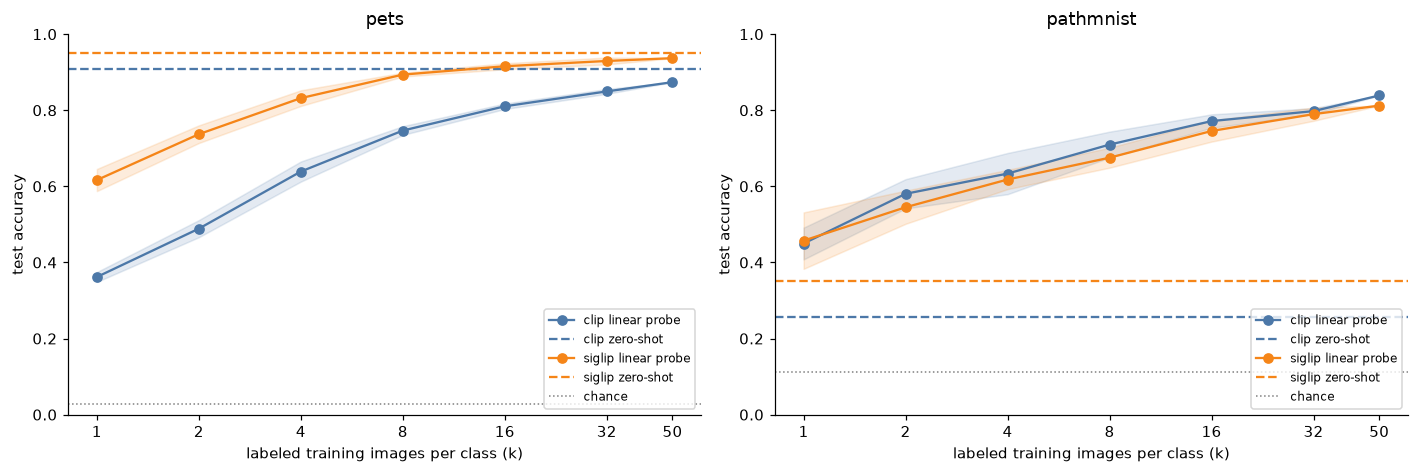

In [4]:
def zero_shot_equivalent_shots(curve_k, curve_acc, zs_acc):
    # Interpolate (in log2 k) the number of labeled images per class a probe needs to match zero-shot.
    if zs_acc <= curve_acc[0]:
        return "< 1"
    for (k0, a0), (k1, a1) in zip(zip(curve_k, curve_acc), zip(curve_k[1:], curve_acc[1:])):
        if a0 < zs_acc <= a1:
            t = (zs_acc - a0) / (a1 - a0)
            return f"≈ {2 ** (np.log2(k0) + t * (np.log2(k1) - np.log2(k0))):.1f}"
    return f"> {curve_k[-1]}"

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
equiv = []
for ax, name in zip(axes, DATASETS):
    for key in MODEL_KEYS:
        d = fs[(fs.dataset == name) & (fs.model == key)].groupby("k").probe.agg(["mean", "std"]).fillna(0)
        ax.plot(d.index, d["mean"], "o-", color=COLORS[key], label=f"{key} linear probe")
        ax.fill_between(d.index, d["mean"] - d["std"], d["mean"] + d["std"], color=COLORS[key], alpha=0.15)
        ax.axhline(zs[key, name]["acc"], color=COLORS[key], ls="--", label=f"{key} zero-shot")
        equiv.append({"dataset": name, "model": key, "zero-shot acc": zs[key, name]["acc"],
                      "labels/class to match zero-shot": zero_shot_equivalent_shots(list(d.index), d["mean"].values, zs[key, name]["acc"])})
    ax.axhline(1 / len(data["clip", name][4]), color="gray", ls=":", lw=1, label="chance")
    ax.set_xscale("log", base=2)
    ax.set_xticks(SHOTS, SHOTS)
    ax.set_ylim(0, 1)
    ax.set_xlabel("labeled training images per class (k)")
    ax.set_ylabel("test accuracy")
    ax.set_title(name)
    ax.legend(fontsize=8, loc="lower right")
fig.tight_layout()
fig.savefig(cu.FIG_DIR / "few_shot_curve.png", bbox_inches="tight")
pd.DataFrame(equiv).style.format({"zero-shot acc": "{:.1%}"})

This is the central plot of the project.

* On **Pets**, the dashed zero-shot line sits high and the probe **never reaches it**, even with all 50 labeled images per class (CLIP: 87.4% probe vs. 90.7% zero-shot; SigLIP: 93.7% vs. 95.0%). A few sentences of text beat 1,850 labeled photos. The CLIP paper reports the same pattern for Oxford Pets; across its benchmarks, zero-shot CLIP matched a 4-shot probe on average and was worth far more on datasets like this one.
* On **PathMNIST**, the zero-shot line sits low, and **a single labeled tile per class** already beats it (~45% vs. 26% / 35%). With 50 per class the probe reaches 81–84%. The image features clearly separate the tissue types (notebook 01's UMAP). What's missing is the **language–image link** for this domain.
* A twist: SigLIP is better than CLIP at zero-shot on both datasets, but CLIP's image features are slightly *better* for probing PathMNIST (83.9% vs. 81.2% at 50/class). The better zero-shot model is not automatically the better feature extractor.

That is the zero-shot vs. linear-probe tradeoff in one figure: zero-shot costs nothing but is capped by how well the model's text side "speaks" your domain. A probe costs labels but only depends on the image features.

## 3. Which classes does the text side fail on?

Per-class accuracy, zero-shot vs. full probe (SigLIP).

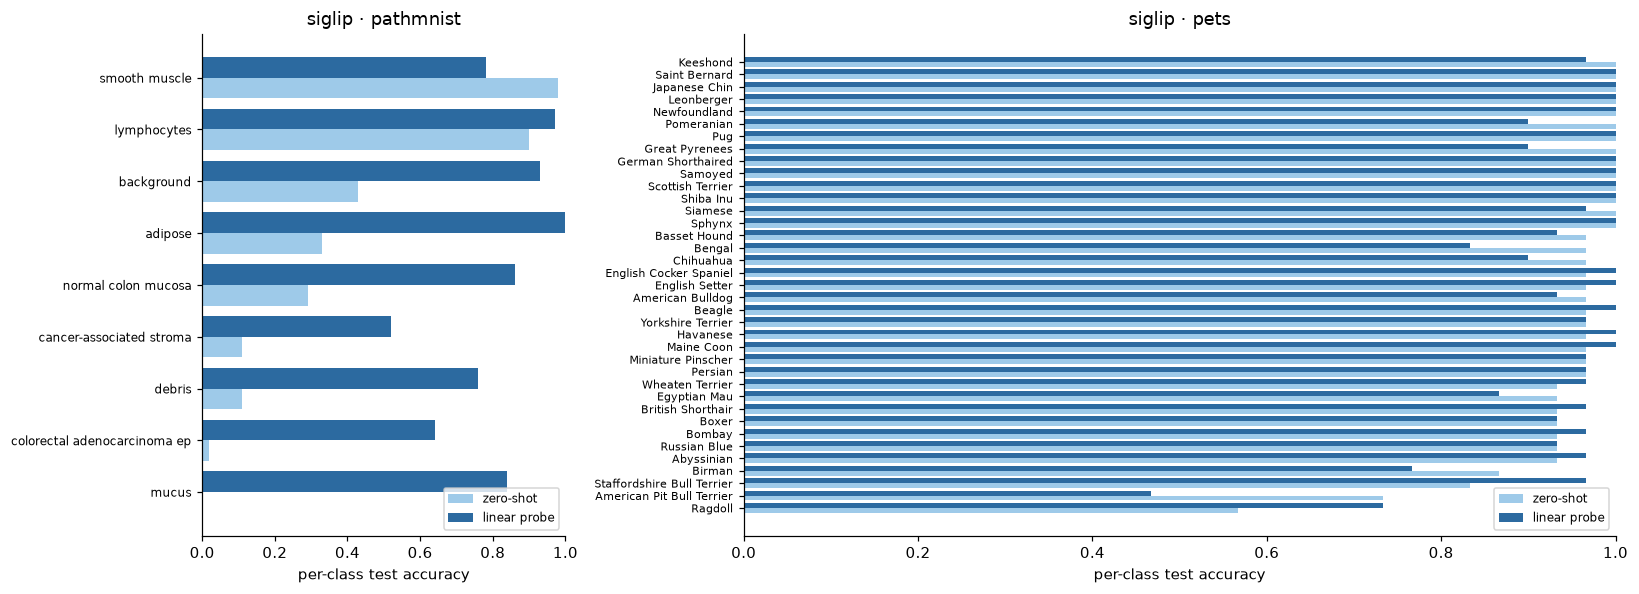

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [1, 2.4]})
key = "siglip"
for ax, name in zip(axes, ["pathmnist", "pets"]):
    Xtr, ytr, Xte, yte, classes = data[key, name]
    zs_pred = (Xte @ zs[key, name]["W"].T).argmax(1)
    pr_pred = probe[key, name].predict(Xte)
    pc = pd.DataFrame({"zero-shot": [(zs_pred[yte == c] == c).mean() for c in range(len(classes))],
                       "linear probe": [(pr_pred[yte == c] == c).mean() for c in range(len(classes))]},
                      index=classes).sort_values("zero-shot")
    y = np.arange(len(pc))
    ax.barh(y - 0.2, pc["zero-shot"], 0.4, label="zero-shot", color="#9ecae9")
    ax.barh(y + 0.2, pc["linear probe"], 0.4, label="linear probe", color="#2c6aa0")
    ax.set_yticks(y, [c[:28] for c in pc.index], fontsize=7 if len(pc) > 10 else 8)
    ax.set_xlim(0, 1)
    ax.set_xlabel("per-class test accuracy")
    ax.set_title(f"{key} · {name}")
    ax.legend(fontsize=8, loc="lower right")
fig.tight_layout()
fig.savefig(cu.FIG_DIR / "per_class.png", bbox_inches="tight")

## 4. Best of both: zero-shot prior + few-shot probe

Zero-shot and a probe make **different kinds of mistakes**: zero-shot errs where language is ambiguous, a few-shot probe errs where its handful of examples was unrepresentative. Combining them can beat both.

The simplest combination: add their log-probabilities, `log p_zero-shot + log p_probe`, and take the argmax. This treats the zero-shot classifier like a prior and the probe like the evidence. (Stronger versions exist: initializing the probe *from* the text weights, or the WiSE-FT and Tip-Adapter methods. The idea is the same.)

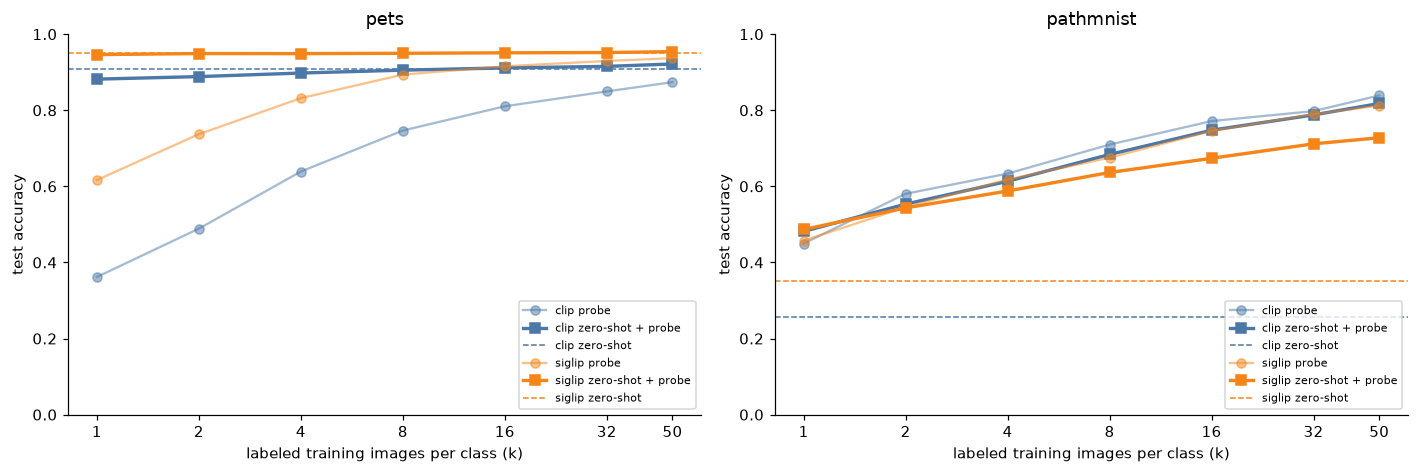

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
for ax, name in zip(axes, DATASETS):
    for key in MODEL_KEYS:
        d = fs[(fs.dataset == name) & (fs.model == key)].groupby("k")[["probe", "blend"]].mean()
        ax.plot(d.index, d["probe"], "o-", color=COLORS[key], alpha=0.5, label=f"{key} probe")
        ax.plot(d.index, d["blend"], "s-", color=COLORS[key], lw=2.2, label=f"{key} zero-shot + probe")
        ax.axhline(zs[key, name]["acc"], color=COLORS[key], ls="--", lw=1, label=f"{key} zero-shot")
    ax.set_xscale("log", base=2)
    ax.set_xticks(SHOTS, SHOTS)
    ax.set_ylim(0, 1)
    ax.set_xlabel("labeled training images per class (k)")
    ax.set_ylabel("test accuracy")
    ax.set_title(name)
    ax.legend(fontsize=7.5, loc="lower right")
fig.tight_layout()
fig.savefig(cu.FIG_DIR / "blend.png", bbox_inches="tight")

When the zero-shot classifier is good (Pets), the blend is better than **both** of its parts at every `k`. At one image per class, CLIP's probe alone gets 36%, the blend 88%. At 50 per class, the blend reaches 92.2% (CLIP) and 95.4% (SigLIP), slightly above zero-shot alone. The few labels fix some of zero-shot's breed confusions without throwing away what the text knows.

When the zero-shot classifier is poor (PathMNIST), the prior only helps at `k = 1` (≈48% vs. 45%) and hurts from `k = 4` on. With SigLIP at 50 per class the blend loses 8 points (72.8% vs. 81.2%), because the confident "smooth muscle" attractor keeps dragging predictions. An equal-weight blend is a blunt tool; in practice the weight would be tuned on validation data, and would end up favoring the probe here.

## 5. Summary

In [7]:
summary = full[["dataset", "model", "zero-shot", "linear probe (50/class)"]].copy()
for k in [1, 4, 16]:
    summary[f"probe k={k}"] = [fs[(fs.dataset == r.dataset) & (fs.model == r.model) & (fs.k == k)].probe.mean() for r in summary.itertuples()]
    summary[f"blend k={k}"] = [fs[(fs.dataset == r.dataset) & (fs.model == r.model) & (fs.k == k)].blend.mean() for r in summary.itertuples()]
summary = summary.merge(pd.DataFrame(equiv)[["dataset", "model", "labels/class to match zero-shot"]], on=["dataset", "model"])
summary.to_csv(cu.RESULTS_DIR / "summary.csv", index=False)
fs.to_csv(cu.RESULTS_DIR / "few_shot.csv", index=False)
summary.style.format({c: "{:.1%}" for c in summary.columns if c not in ("dataset", "model", "labels/class to match zero-shot")})

,dataset,model,zero-shot,linear probe (50/class),probe k=1,blend k=1,probe k=4,blend k=4,probe k=16,blend k=16,labels/class to match zero-shot
0,pets,clip,90.7%,87.0%,36.2%,88.2%,63.9%,89.8%,81.0%,91.1%,> 50
1,pets,siglip,95.0%,94.0%,61.7%,94.6%,83.2%,94.9%,91.6%,95.1%,> 50
2,pathmnist,clip,25.6%,83.4%,45.0%,48.2%,63.4%,61.3%,77.2%,74.8%,< 1
3,pathmnist,siglip,35.2%,81.1%,45.7%,48.7%,61.8%,58.8%,74.6%,67.4%,< 1


## Takeaways

| | Zero-shot | Linear probe |
|---|---|---|
| Labels needed | none | some (accuracy grows with more) |
| What it relies on | the **text–image alignment** for your domain | only the **image features** |
| Cost to add a class | write a sentence | collect and label images, retrain |
| Typical failure | domain the captions never covered (histology), ambiguous class names | too few or unrepresentative examples |
| Typical use | quick triage, open-ended labels, bootstrapping a labeling effort | fixed label set with some labeled data |

* **Pets** sits on the zero-shot-friendly side: zero-shot is worth more than 50 labeled examples per class.
* **PathMNIST** sits on the other side: the image features are good, the language bridge is not. For bio images, either probe a general model with a few labels, or use a domain-specific vision–language model (e.g. CONCH, PLIP, QuiltNet, BiomedCLIP) and redo notebook 02. See the README's "Extensions" section.